# WhatsApp Chat Analysis with NLP


In [233]:
# imoprting library
import re
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jaipr\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [234]:
# Load the chat file
def load_chat(filepath):
    with open(filepath, 'r', encoding='utf-8') as file:
        chat_data = file.readlines()
    return chat_data


In [235]:
chat_data = load_chat('whatsapp_chat_with_system_and_media.txt') 


In [236]:
# convert chat into a DataFrame
def parse_chat(chat_data):
    messages = []
    dates = []
    users = []
    pattern = r'(\d{1,2}/\d{1,2}/\d{2,4}),\s(\d{1,2}:\d{2}(?:\s[APap][Mm]))\s-\s([^:]+):\s(.+)'
    for line in chat_data:
        match = re.match(pattern, line)
        if match:
            date, time, user, message = match.groups()
            dates.append(f"{date} {time}")
            users.append(user)
            messages.append(message)
    df = pd.DataFrame({'datetime': dates, 'user': users, 'message': messages})
    df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
    return df


In [237]:
df.head()

,datetime,user,message
0,2025-03-20 09:00:00,Charlie,Oh yesss That one’s wild 🙌😎
1,2025-03-20 09:03:00,Alice,Don't forget the charger 😂
2,2025-03-20 09:02:00,Bob,Did you see the news today? 👽
3,2025-03-20 09:09:00,Alice,What time are we meeting? 🧃🧃
4,2025-03-20 09:12:00,Bob,Good luck with the interview! 🙌🙌


In [238]:
df = parse_chat(chat_data)


C:\Users\jaipr\AppData\Local\Temp\ipykernel_10964\740187210.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')


In [239]:
# Basic stats
def chat_stats(df):
    print(f"Total Messages: {df.shape[0]}")
    print(f"Total Users: {df['user'].nunique()}")
    print("\nMost Active Users:")
    print(df['user'].value_counts().head(5))


In [240]:
chat_stats(df)


Total Messages: 974
Total Users: 3

Most Active Users:
user
Alice      350
Charlie    328
Bob        296
Name: count, dtype: int64


In [241]:
# Word frequency
def most_common_words(df, n=20):
    stop_words = set(stopwords.words('english'))
    words = []
    for msg in df['message']:
        msg = re.sub(r'[^a-zA-Z\s]', '', msg)
        for word in msg.lower().split():
            if word not in stop_words and len(word) > 1:
                words.append(word)
    counter = Counter(words)
    return counter.most_common(n)



In [242]:
print("\nMost Common Words:")
common_words = most_common_words(df)
for word, freq in common_words:
    print(f"{word}: {freq}")



Most Common Words:
media: 81
omitted: 81
im: 77
night: 76
good: 65
haha: 63
bring: 58
meeting: 51
time: 50
lets: 48
game: 48
soon: 48
see: 47
weekend: 41
nice: 35
anything: 35
yeah: 34
started: 34
new: 34
scifi: 34


In [243]:
from nltk.sentiment import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()
df['sentiment'] = df['message'].apply(lambda x: sia.polarity_scores(x)['compound'])



[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\jaipr\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


## sentiment analysis based on category

In [244]:

def categorize_sentiment(score):
    if score > 0.05:
        return 'Positive'
    elif score < -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_category'] = df['sentiment'].apply(categorize_sentiment)


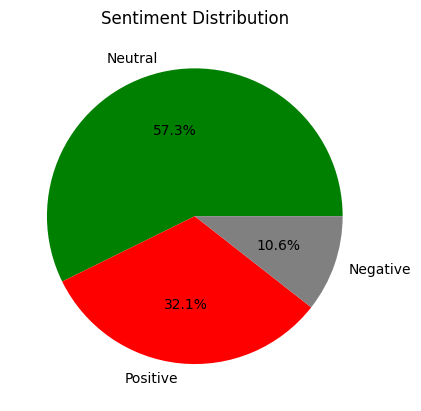

In [245]:
# Plot sentiment distribution
df['sentiment_category'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['green', 'red', 'grey'])
plt.title('Sentiment Distribution')
plt.ylabel('')
plt.show()


##  plot average sentiment per user



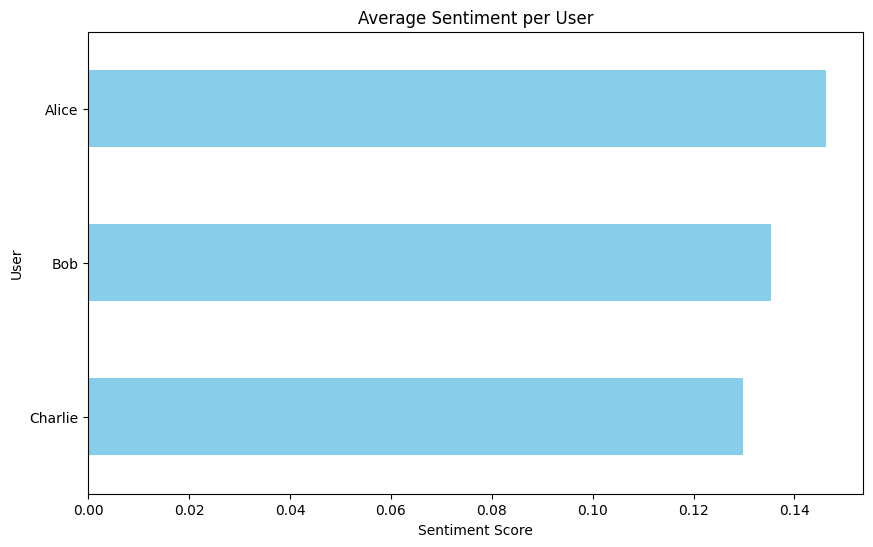

In [246]:
import matplotlib.pyplot as plt

# Average sentiment by user
user_sentiment = df.groupby('user')['sentiment'].mean().sort_values()

user_sentiment.plot(kind='barh', figsize=(10,6), color='skyblue')
plt.title('Average Sentiment per User')
plt.xlabel('Sentiment Score')
plt.ylabel('User')
plt.show()


# Sentiment over time


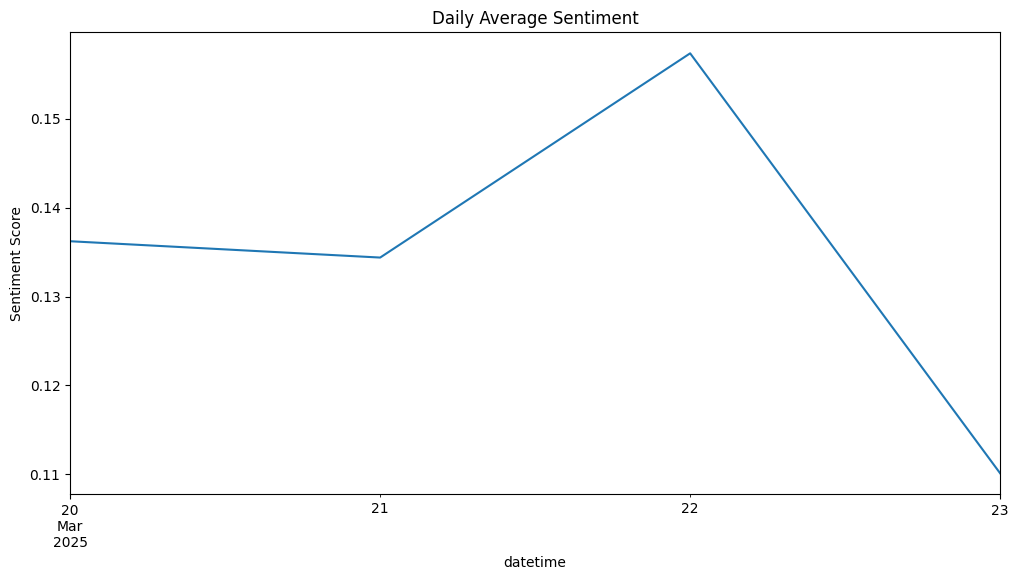

In [247]:
df.set_index('datetime')['sentiment'].resample('D').mean().plot(figsize=(12,6))
plt.title('Daily Average Sentiment')
plt.ylabel('Sentiment Score')
plt.show()


# Time Series Analysis
### When do people chat the most?
> features like:
>Hourly activity,
>Day of week analysis,
>Monthly trend


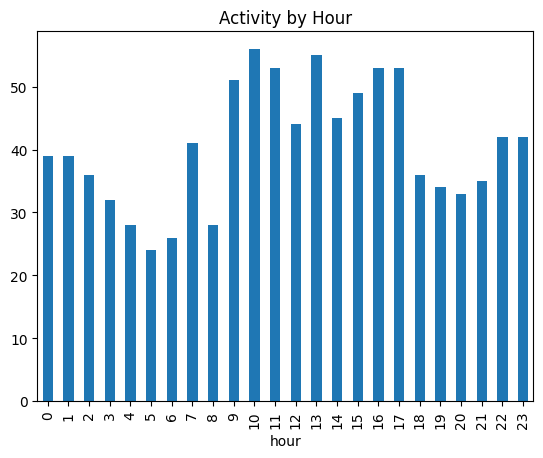

In [248]:
df['hour'] = df['datetime'].dt.hour
df['day'] = df['datetime'].dt.day_name()
df['month'] = df['datetime'].dt.month_name()

# Plotting example
df['hour'].value_counts().sort_index().plot(kind='bar')
plt.title('Activity by Hour')
plt.show()


# Emoji Analysis (😂🔥❤️)
### Emojis are a big part of WhatsApp chats.

Here, we can extract and count them separately!


In [249]:
import emoji

def extract_emojis(s):
    return ''.join(c for c in s if c in emoji.EMOJI_DATA)

df['emojis'] = df['message'].apply(extract_emojis)

# Count most used emojis
all_emojis = ''.join(df['emojis'].tolist())
emoji_counter = Counter(all_emojis)
print(emoji_counter.most_common(10))


[('😎', 148), ('🔥', 139), ('👽', 130), ('🥞', 120), ('🚀', 119), ('😊', 113), ('🍳', 111), ('🧃', 106), ('😂', 101), ('🙌', 100)]


# Topic Modeling
### Find main topics people are discussing.
### Using LDA (Latent Dirichlet Allocation) from gensim

In [250]:
from gensim import corpora, models

texts = [msg.split() for msg in df['message']]
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]
lda = models.LdaModel(corpus, num_topics=5, id2word=dictionary, passes=15)

for idx, topic in lda.print_topics(-1):
    print(f"Topic {idx}: {topic}")


Topic 0: 0.082*"<Media" + 0.082*"omitted>" + 0.038*"that" + 0.035*"Netflix" + 0.035*"started" + 0.035*"series" + 0.035*"Yeah," + 0.035*"sci-fi" + 0.035*"new" + 0.035*"on"
Topic 1: 0.042*"Anything" + 0.042*"good?" + 0.042*"Haha" + 0.042*"nice!" + 0.035*"Anyone" + 0.035*"coffee?" + 0.035*"wants" + 0.034*"y’all" + 0.034*"Miss" + 0.034*"❤️"
Topic 2: 0.044*"the" + 0.037*"we" + 0.037*"are" + 0.022*"with" + 0.022*"interview!" + 0.022*"Good" + 0.022*"luck" + 0.022*"Don't" + 0.022*"charger" + 0.022*"forget"
Topic 3: 0.043*"night" + 0.043*"soon" + 0.043*"do" + 0.043*"Let's" + 0.043*"game" + 0.043*"a" + 0.026*"That" + 0.026*"one’s" + 0.026*"Oh" + 0.026*"wild"
Topic 4: 0.038*"I’m" + 0.037*"of" + 0.027*"your" + 0.026*"😎" + 0.026*"🎮" + 0.026*"Bring" + 0.026*"Switch!" + 0.022*"it" + 0.022*"tonight" + 0.022*"Ok"


In [251]:
from nltk.sentiment import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()
df['sentiment'] = df['message'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Now you can plot average sentiment per user or per day!


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\jaipr\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


## Network Analysis
Who talks with whom the most? (only for a group chat)
Build a user interaction network graph using networkx.

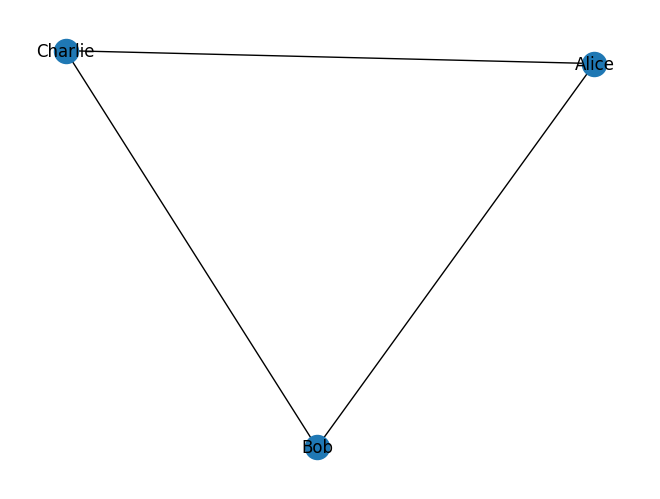

In [252]:
import networkx as nx

G = nx.Graph()

for i in range(1, len(df)):
    if df.iloc[i-1]['user'] != df.iloc[i]['user']:
        G.add_edge(df.iloc[i-1]['user'], df.iloc[i]['user'])

nx.draw(G, with_labels=True)
plt.show()


# Generate word cloud


In [253]:
def generate_wordcloud(df):
    text = " ".join(msg for msg in df['message'])
    wordcloud = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords.words('english')).generate(text)
    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    
    plt.show()




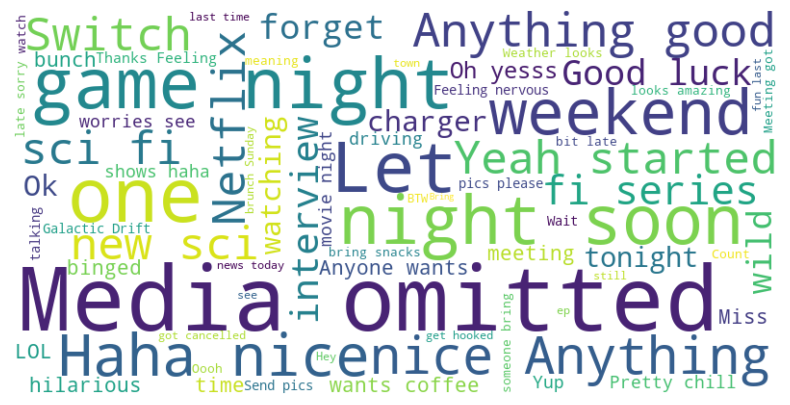

In [254]:
generate_wordcloud(df)
